# 06 · Attention, from scratch
**Kuizi brain walkthrough, notebook 6 of 10**

When a student faces an **RLC** question, which past answers tell us most? Probably their answers
on RC, RL and differential equations, more than their answers on vectors. **Attention** is a way
for a model to decide, for each new question, *how much to look at each past answer*.

Three roles, like a library search:
- **Query** (Q): what I am looking for now (the current question).
- **Keys** (K): the label on each past item (what it is about).
- **Values** (V): what each past item contains (here, was the answer right or wrong).

Score = how well the query matches each key. **Softmax** turns scores into weights that add up to 1.
The output is the weighted average of the values:

  Attention(Q, K, V) = softmax( Q·Kᵀ / √d ) · V

| In this notebook | Production ticket |
| --- | --- |
| SAINT+ attention layers | T042 |
| Attention-based explanations | T049, T177 |

<div dir="rtl" lang="ar">

## ٠٦ · آلية الانتباه، من الصفر

عندما يواجه التلميذ سؤالًا في <b>RLC</b>، أي الإجابات السابقة تخبرنا أكثر؟ غالبًا إجاباته في RC وRL والمعادلات التفاضلية،
أكثر من إجاباته في الأشعة. <b>الانتباه</b> طريقة تجعل النموذج يقرّر، لكل سؤال جديد، <b>كم ينظر إلى كل إجابة سابقة</b>.

ثلاثة أدوار، مثل البحث في مكتبة: <b>الاستعلام</b> Q (ما أبحث عنه الآن)، <b>المفاتيح</b> K (عنوان كل تمرين سابق)،
و<b>القيم</b> V (محتوى كل تمرين سابق: هل كانت الإجابة صحيحة). الدرجة = مدى تطابق الاستعلام مع كل مفتاح،
ودالة <b>softmax</b> تحوّل الدرجات إلى أوزان مجموعها 1، والمخرج هو المتوسّط الموزون للقيم.

</div>

In [1]:
# Concept: attention by hand on six past answers · Production: T042
import numpy as np, pandas as pd
concepts = ["vect", "deriv", "eqdiff", "rc", "rl", "rlc"]
# Each concept as a small vector: which "family" it belongs to (maths, differential equations, circuits).
features = {"vect": [1, 0, 0], "deriv": [1, .6, 0], "eqdiff": [.4, 1, .3], "rc": [0, .8, 1], "rl": [0, .8, 1], "rlc": [0, .6, 1.2]}
history = [("vect", 1), ("deriv", 0), ("eqdiff", 0), ("rc", 1), ("rl", 0)]
K = np.array([features[c] for c, _ in history])          # keys: what each past item is about
V = np.array([[1.0] if y else [-1.0] for _, y in history])  # values: +1 right, -1 wrong
q = np.array(features["rlc"])                            # query: the new RLC question
d = len(q)
scores = K @ q / np.sqrt(d)
weights = np.exp(scores) / np.exp(scores).sum()          # softmax
output = weights @ V
pd.DataFrame({"past item": [c for c, _ in history], "answer": ["right" if y else "wrong" for _, y in history],
              "score": scores.round(2), "weight": weights.round(2)})

,past item,answer,score,weight
0,vect,right,0.00,0.11
1,deriv,wrong,0.21,0.13
2,eqdiff,wrong,0.55,0.19
3,rc,right,0.97,0.29
4,rl,wrong,0.97,0.29


In [2]:
# Concept: reading the result · Production: T042, T049
print(f"Weighted evidence for the RLC question: {output[0]:+.2f} (from -1 = all wrong to +1 = all right)")
top = np.argsort(weights)[::-1][:2]
print("The two answers that weigh most:", [history[i][0] for i in top])

Weighted evidence for the RLC question: -0.21 (from -1 = all wrong to +1 = all right)
The two answers that weigh most: ['rl', 'rc']


## No peeking at the future: the causal mask

When predicting answer number *t*, the model must never see that answer or anything after it.
A **causal mask** forbids every look into the future: position *t* may look at positions 1 to *t*,
never beyond. Position *t* itself is allowed because SAINT+ shifts its inputs: at position *t* it
holds the **current question** and the **previous** answer, never the answer it is predicting.
Below, a cross (✕) means "forbidden".

<div dir="rtl" lang="ar">

## لا نظر إلى المستقبل: القناع السببي

عند التنبّؤ بالإجابة رقم t، يجب ألّا يرى النموذج تلك الإجابة ولا ما بعدها. <b>القناع السببي</b> يمنع كل نظر إلى المستقبل:
الموضع t ينظر إلى المواضع من 1 إلى t فقط. ويُسمح بالموضع t نفسه لأن SAINT+ يزيح مدخلاته: في الموضع t يوجد
<b>السؤال الحالي</b> و<b>الإجابة السابقة</b>، وليس الإجابة المطلوب التنبّؤ بها أبدًا. العلامة ✕ في الجدول تعني "ممنوع".

</div>

In [3]:
# Concept: causal mask · Production: T042
from kuizi_brain.models import causal_mask
L = 6
mask = causal_mask(L).numpy()
pd.DataFrame(np.where(mask, "✕", "✓"), index=[f"predicting step {i+1}" for i in range(L)],
             columns=[f"looks at {j+1}" for j in range(L)])

,looks at 1,looks at 2,looks at 3,looks at 4,looks at 5,looks at 6
predicting step 1,✓,✕,✕,✕,✕,✕
predicting step 2,✓,✓,✕,✕,✕,✕
predicting step 3,✓,✓,✓,✕,✕,✕
predicting step 4,✓,✓,✓,✓,✕,✕
predicting step 5,✓,✓,✓,✓,✓,✕
predicting step 6,✓,✓,✓,✓,✓,✓


## Several heads look at different things

Real models use several **heads** in parallel. Each head has its own way of building queries and
keys, so one head can focus on related concepts while another focuses on recent answers. Here we
build two heads by hand on a longer history and draw where each one looks.

<div dir="rtl" lang="ar">

## عدّة رؤوس تنظر إلى أشياء مختلفة

النماذج الحقيقية تستعمل عدّة <b>رؤوس</b> بالتوازي. لكل رأس طريقته في بناء الاستعلامات والمفاتيح، فيركّز رأس على
المفاهيم المرتبطة ويركّز آخر على الإجابات الحديثة. نبني هنا رأسين يدويًا على تاريخ أطول ونرسم أين ينظر كل منهما.

</div>

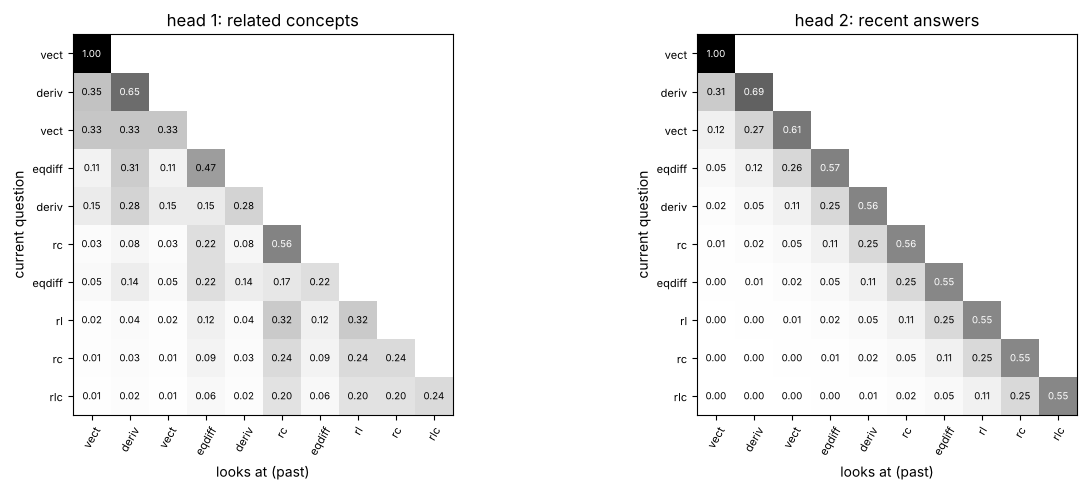

In [4]:
# Concept: two attention heads: concept similarity and recency · Production: T042, T049
import matplotlib.pyplot as plt
seq = ["vect", "deriv", "vect", "eqdiff", "deriv", "rc", "eqdiff", "rl", "rc", "rlc"]
F = np.array([features[c] for c in seq])
L = len(seq)
def attend(scores):
    scores = np.where(causal_mask(L).numpy(), -np.inf, scores)
    w = np.exp(scores - scores.max(1, keepdims=True))
    return w / w.sum(1, keepdims=True)
concept_head = attend(3 * F @ F.T / np.sqrt(3))
pos = np.arange(L)
recency_head = attend(-0.8 * np.abs(pos[:, None] - pos[None, :]).astype(float))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, w, title in [(axes[0], concept_head, "head 1: related concepts"), (axes[1], recency_head, "head 2: recent answers")]:
    ax.imshow(w, cmap="Greys", vmin=0, vmax=1)
    for i in range(L):
        for j in range(i + 1):
            ax.text(j, i, f"{w[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if w[i, j] > .5 else "black")
    ax.set_xticks(range(L)); ax.set_xticklabels(seq, rotation=60, fontsize=8)
    ax.set_yticks(range(L)); ax.set_yticklabels(seq, fontsize=8)
    ax.set_xlabel("looks at (past)"); ax.set_ylabel("current question"); ax.set_title(title)
plt.tight_layout(); plt.show()

## The same thing in PyTorch

The library layer `nn.MultiheadAttention`, used by SAINT+, does exactly this calculation, plus
learned projections that turn each input into its query, key and value. With the projections set
to "do nothing", it gives our hand-made numbers back.

<div dir="rtl" lang="ar">

## نفس الشيء في PyTorch

الطبقة الجاهزة <code>nn.MultiheadAttention</code> التي يستعملها SAINT+ تقوم بنفس الحساب، مع إسقاطات متعلَّمة تحوّل
كل مدخل إلى استعلام ومفتاح وقيمة. عندما نجعل الإسقاطات "لا تفعل شيئًا"، تعيد لنا نفس أرقامنا اليدوية.

</div>

In [5]:
# Concept: checking our formula against PyTorch · Production: T042
import torch
from torch import nn
x = torch.tensor(F, dtype=torch.float32)[None]          # (batch=1, L, d=3)
layer = nn.MultiheadAttention(embed_dim=3, num_heads=1, bias=False, batch_first=True)
with torch.no_grad():
    layer.in_proj_weight.copy_(torch.cat([torch.eye(3)] * 3))   # Q = K = V = input
    layer.out_proj.weight.copy_(torch.eye(3))
_, w_torch = layer(x, x, x, attn_mask=causal_mask(L), need_weights=True)
manual = attend(F @ F.T / np.sqrt(3))
print("largest difference between PyTorch and our formula:", float(np.abs(w_torch[0].detach().numpy() - manual).max()))

largest difference between PyTorch and our formula: 1.5331274416663376e-08


### Remember
- Attention = for each new question, a weighted look at every past answer; weights come from query–key similarity.
- Softmax makes the weights positive and adding up to 1; the causal mask forbids looking at the future.
- Several heads look at different things (related concepts, recency…).
- The weights are readable: Kuizi can show *which* past answers drove an estimate (T049, T177).

<div dir="rtl" lang="ar">

### تذكّر
- الانتباه = لكل سؤال جديد نظرة موزونة إلى كل إجابة سابقة، والأوزان من تشابه الاستعلام والمفتاح.
- softmax تجعل الأوزان موجبة ومجموعها 1، والقناع السببي يمنع النظر إلى المستقبل.
- عدّة رؤوس تنظر إلى أشياء مختلفة (المفاهيم المرتبطة، الإجابات الحديثة…).
- الأوزان مقروءة: يستطيع كويزي أن يُظهر <b>أي</b> الإجابات السابقة أثّرت في التقدير (T049، T177).

</div>